In [1]:
from bs4 import BeautifulSoup
import urllib.request
import pandas as pd
import datetime
import requests
from selenium import webdriver
from selenium.webdriver.common.by import By
import time
from collections import defaultdict
import random

C:\Users\smart\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53804 (\N{HANGUL SYLLABLE TU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\smart\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\smart\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\smart\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


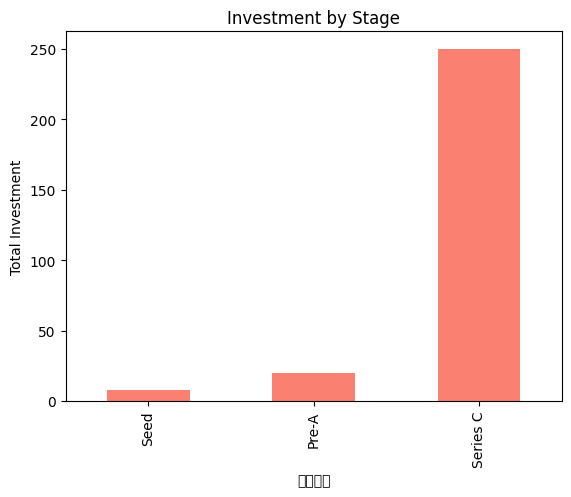

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 데이터 프레임 준비 (예시)
df = pd.read_csv('C:/Users/smart/OneDrive/바탕 화면/코드/m&a_detail_투자 유치_2.csv')
df = pd.DataFrame({
    '투자단계': ['Series C', 'Seed', 'Pre-A', 'Seed', 'Series C'],
    '투자금액': [100, 5, 20, 3, 150]
})

# 2. 투자 단계의 우선순위(순서) 정의
order = ['Seed', 'Pre-A', 'Pre-IPO' ,'Series A', 'Series B', 'Series C']

# 3. '투자단계' 컬럼을 순서가 있는 범주형(Categorical) 데이터로 변환
df['투자단계'] = pd.Categorical(df['투자단계'], categories=order, ordered=True)

# 4. 단계별로 정렬
df_sorted = df.sort_values('투자단계')

# 5. 시각화 (Pandas 기본 내장 기능 사용)
df_sorted.groupby('투자단계')['투자금액'].sum().plot(kind='bar', color='salmon')
plt.title('Investment by Stage')
plt.ylabel('Total Investment')
plt.show()

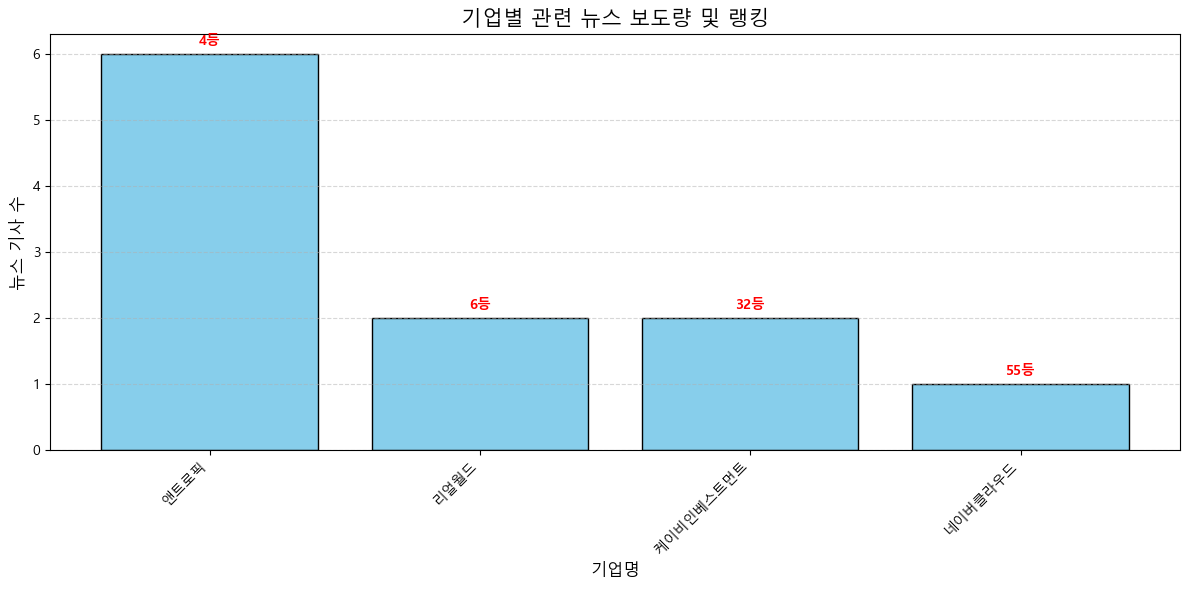

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 데이터 불러오기
rank_df = pd.read_csv('C:/Users/smart/OneDrive/바탕 화면/코드/rank_data_0.csv', encoding='cp949')
news_df = pd.read_csv('C:/Users/smart/OneDrive/바탕 화면/코드/뉴스_.csv', encoding='utf-8-sig')

# 2. 순위 정보 추가 (rank_data_0.csv의 등장 순서를 순위로 가정)
# '전체' 탭에서 기업이 등장하는 순서를 등수로 정의합니다.
rank_df['등수'] = rank_df.index + 1 

# 3. 데이터 병합
merged_df = pd.merge(rank_df, news_df, left_on='기업명', right_on='관련기업', how='inner')

# 4. 기업별 뉴스 건수와 등수를 정리
# 한 기업이 여러 뉴스에 나올 수 있으므로, 가장 높은 순위(min)를 사용
summary = merged_df.groupby('기업명').agg({'기사제목': 'count', '등수': 'min'})
summary = summary.sort_values(by='기사제목', ascending=False)

# 5. 시각화: 막대 그래프 + 텍스트 레이블(등수)
plt.figure(figsize=(12, 6))
bars = plt.bar(summary.index, summary['기사제목'], color='skyblue', edgecolor='black')

# 막대 위에 등수 표시
for bar, rank in zip(bars, summary['등수']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
             f'{rank}등', ha='center', va='bottom', fontsize=10, fontweight='bold', color='red')

plt.title('기업별 관련 뉴스 보도량 및 랭킹', fontsize=15)
plt.xlabel('기업명', fontsize=12)
plt.ylabel('뉴스 기사 수', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()